# Clustering in practice — library lab

Hands-on companion to [README §2.2, §7 and §9](../../README.md#7-judging-a-clustering). It uses the ready-made implementations in **scikit-learn** and **SciPy**;
it introduces no new algorithm, so it has no from-scratch twin.

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers). After that, run the labs in order (`Shift + Enter` cell by cell, or
   **Run All**). Labs only reuse things from earlier cells, so top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output: try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

**One score used everywhere:** the data in these labs comes with the "true" groups it was generated from, which a real
clustering problem doesn't have. We use them only to *grade* a result with the **adjusted Rand index (ARI)**: 1 = the
clusters match the true groups exactly, 0 = no better than random labels (it can dip slightly below 0).

| Lab | What it shows |
|---|---|
| [10](#lab-10) | scale the features first |
| [11](#lab-11) | scoring clusters without labels, and how the scores mislead |
| [12](#lab-12) | every method on iris, wine and digits |
| [Which algorithm when](#guide) | a decision guide |
| [Summary](#summary) | one line per lab |

Everything runs offline: the data is generated in the notebook or ships with scikit-learn.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN, HDBSCAN, OPTICS, AgglomerativeClustering, KMeans
from sklearn.datasets import load_digits, load_iris, load_wine, make_moons
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.preprocessing import StandardScaler


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def plot_clusters(ax, X, labels, title, centers=None):
    """Scatter 2-D points coloured by cluster label. Label -1 (noise) is drawn as small grey crosses,
    optional `centers` as black stars."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="*", s=200, label="centroid")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")

<a id="lab-10"></a>

## Lab 10 · Scale the features first

**Goal:** every method here measures distances, and a distance adds up the squared differences of all features, so a
feature measured in large numbers dominates (README §2.2). The wine data has 13 chemical measurements of 178 wines
from 3 cultivars, in very different units.

feature spreads (std) range from 0.12 (nonflavanoid_phenols) to 314 (proline)
ARI with the 3 grape cultivars:        raw    standardised
  k-means (k = 3)                    0.37    0.90
  agglomerative, ward                0.37    0.79


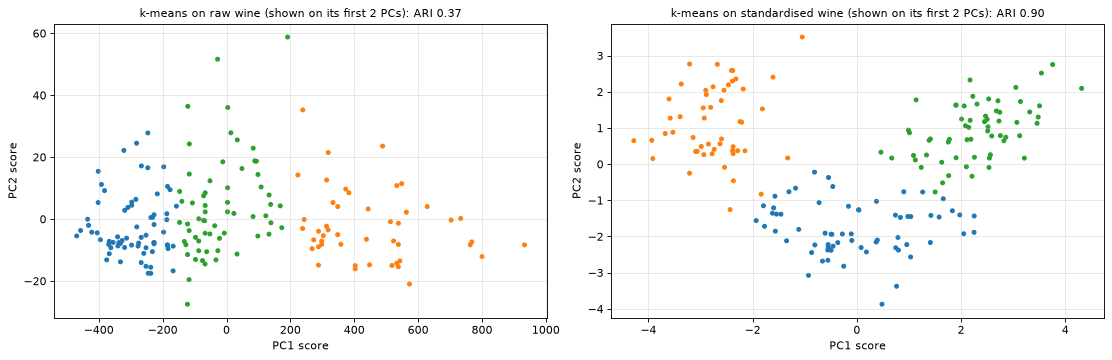

In [2]:
wine = load_wine()
wine_scaled = StandardScaler().fit_transform(wine.data)
print("feature spreads (std) range from", f"{wine.data.std(axis=0).min():.2f} ({wine.feature_names[wine.data.std(axis=0).argmin()]})",
      "to", f"{wine.data.std(axis=0).max():.0f} ({wine.feature_names[wine.data.std(axis=0).argmax()]})")
print("ARI with the 3 grape cultivars:        raw    standardised")
for name, model in [("k-means (k = 3)", KMeans(3, n_init=10, random_state=SEED)),
                    ("agglomerative, ward", AgglomerativeClustering(3, linkage="ward"))]:
    raw = adjusted_rand_score(wine.target, model.fit_predict(wine.data))
    scaled = adjusted_rand_score(wine.target, model.fit_predict(wine_scaled))
    print(f"  {name:22s}            {raw:5.2f}   {scaled:5.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, data, title in [(axes[0], wine.data, "raw"), (axes[1], wine_scaled, "standardised")]:
    two = PCA(2).fit_transform(data)                                    # a 2-D view only, clustering used all 13 columns
    labels = KMeans(3, n_init=10, random_state=SEED).fit_predict(data)
    plot_clusters(ax, two, labels, f"k-means on {title} wine (shown on its first 2 PCs): "
                  f"ARI {adjusted_rand_score(wine.target, labels):.2f}")
    ax.set_xlabel("PC1 score"); ax.set_ylabel("PC2 score")
plt.tight_layout(); plt.show()

> **How to read this**
> * Feature spreads range from **0.12** (nonflavanoid phenols) to **314** (proline). Unscaled, the distance between two
>   wines is essentially their difference in proline.
> * **k-means:** ARI **0.37** on raw data → **0.90** after standardising (each feature: subtract its mean, divide by its
>   standard deviation). **Ward:** 0.37 → 0.79.
> * The plots show both results on the data's first 2 principal components (a 2-D view only; the clustering used all 13
>   columns). Raw: the clusters are slices of proline. Standardised: three clean groups.
> * Standardise unless the units really are comparable (e.g. all pixels, all coordinates in metres). The PCA lab makes
>   the same point for PCA (Lab 10).

<a id="lab-11"></a>

## Lab 11 · Scoring a clustering without true labels

**Goal:** real clustering problems have no true groups, so the scores that need them (ARI, NMI) are unavailable.
**Internal** scores judge the clusters from the data alone (README §7). Compare them on the moons, where DBSCAN is
right and k-means is wrong.

<details>
<summary><b>The five scores (click to expand)</b></summary>

**Need the true labels** (useful for testing a method on data where the answer is known):

* **ARI (adjusted Rand index):** of all pairs of points, how often the clustering and the truth agree on "same group"
  vs "different groups", corrected so that random labels score 0. Max 1.
* **NMI (normalised mutual information):** how much knowing a point's cluster tells you about its true group, scaled
  to 0–1.

**Need only the data:**

* **Silhouette** ([Lab 3](../01-kmeans/kmeans_lab.ipynb#lab-3)): tight-and-separated per point, averaged. −1 to 1, higher is better.
* **Davies–Bouldin:** for each cluster, the worst ratio (spread of cluster i + spread of cluster j) / distance between
  their centres; averaged. Lower is better, 0 is best.
* **Calinski–Harabasz:** between-cluster variance / within-cluster variance, adjusted for the number of clusters.
  Higher is better.

All three internal scores are built from centres, averages or distances to the nearest cluster, so they reward
**round, well-separated** clusters.

</details>

                        ARI    NMI | silhouette  Davies-Bouldin  Calinski-Harabasz
                      needs labels | higher=better    lower=better      higher=better
k-means (k = 2)        0.25   0.19 |       0.49            0.78                740
DBSCAN (eps = 0.15)    1.00   0.99 |       0.05            1.13                163


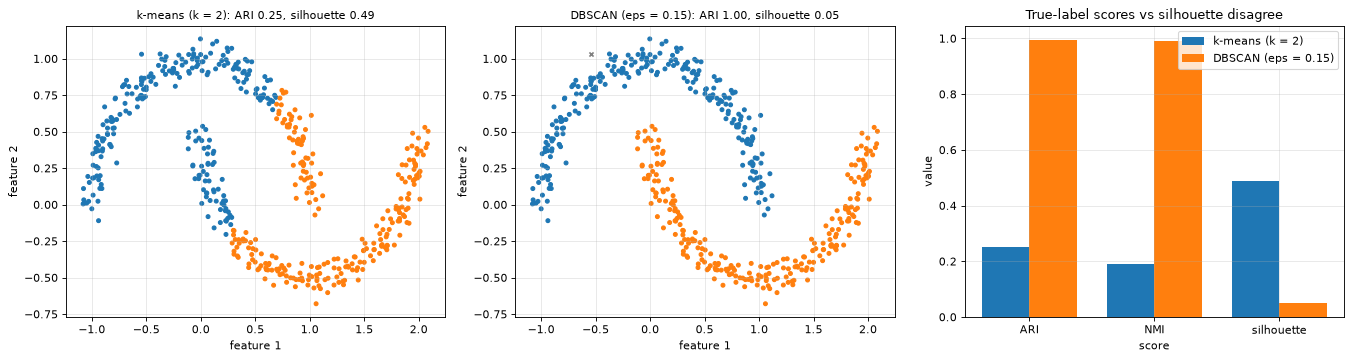

In [3]:
X11, y11 = make_moons(500, noise=0.06, random_state=SEED)
candidates = {"k-means (k = 2)": KMeans(2, n_init=10, random_state=SEED).fit_predict(X11),
              "DBSCAN (eps = 0.15)": DBSCAN(eps=0.15, min_samples=5).fit_predict(X11)}
rows = {}
print(f"{'':20s} {'ARI':>6s} {'NMI':>6s} | {'silhouette':>10s} {'Davies-Bouldin':>15s} {'Calinski-Harabasz':>18s}")
print(f"{'':20s} {'needs labels':>13s} | {'higher=better':>10s} {'lower=better':>15s} {'higher=better':>18s}")
for name, labels in candidates.items():
    rows[name] = [adjusted_rand_score(y11, labels), normalized_mutual_info_score(y11, labels),
                  silhouette_score(X11, labels), davies_bouldin_score(X11, labels), calinski_harabasz_score(X11, labels)]
    print(f"{name:20s} {rows[name][0]:6.2f} {rows[name][1]:6.2f} | {rows[name][2]:10.2f} {rows[name][3]:15.2f} {rows[name][4]:18.0f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (name, labels) in zip(axes, candidates.items()):
    plot_clusters(ax, X11, labels, f"{name}: ARI {rows[name][0]:.2f}, silhouette {rows[name][2]:.2f}")
metric_names = ["ARI", "NMI", "silhouette"]
width = 0.38
for i, (name, values) in enumerate(rows.items()):
    axes[2].bar(np.arange(3) + i * width, values[:3], width, label=name)
axes[2].set_xticks(np.arange(3) + width / 2, metric_names)
axes[2].set_xlabel("score"); axes[2].set_ylabel("value"); axes[2].set_title("True-label scores vs silhouette disagree")
axes[2].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * The true-label scores agree: DBSCAN is right (**ARI 1.00, NMI 0.99**), k-means is wrong (**0.25, 0.19**).
> * Every internal score prefers the **wrong** answer: silhouette **0.49** for k-means vs **0.05** for DBSCAN;
>   Davies–Bouldin 0.78 vs 1.13 (lower is "better"); Calinski–Harabasz 740 vs 163.
> * Why: two interleaved crescents are not "compact and far apart". Many points on one moon are closer to the other
>   moon's points than to the far end of their own moon, so their silhouette is low or negative.
> * Internal scores are fine for comparing k within one method that makes round clusters ([Lab 3](../01-kmeans/kmeans_lab.ipynb#lab-3)). Across methods, or
>   for non-round clusters, they can mislead: look at the clusters and check whether they mean something.

<a id="lab-12"></a>

## Lab 12 · All methods on real data

**Goal:** run the methods side by side on three real datasets that ship with scikit-learn, all standardised (digits
reduced to 20 principal components first, as in the PCA lab's Lab 17). The centroid and hierarchical methods get the
true number of clusters; HDBSCAN and OPTICS decide it themselves. ARI counts noise points as one extra group.


iris (4 columns)  (true clusters: 3)
  method                   ARI  noise  clusters  seconds
  k-means                 0.62     0%         3    0.003
  agglomerative ward      0.62     0%         3    0.000
  agglomerative single    0.56     0%         3    0.000
  HDBSCAN                 0.56     1%         2    0.001
  OPTICS (xi)             0.40    13%         3    0.041

wine (13 columns)  (true clusters: 3)
  method                   ARI  noise  clusters  seconds
  k-means                 0.90     0%         3    0.003
  agglomerative ward      0.79     0%         3    0.000
  agglomerative single   -0.01     0%         3    0.000
  HDBSCAN                 0.26    42%         2    0.001
  OPTICS (xi)             0.00     0%         1    0.048

digits (64 → 20 PCs)  (true clusters: 10)
  method                   ARI  noise  clusters  seconds
  k-means                 0.67     0%        10    0.038
  agglomerative ward      0.78     0%        10    0.021
  agglomerative single   

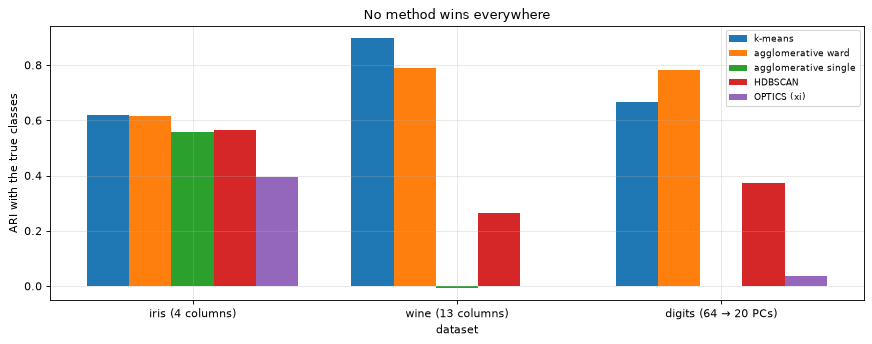

In [4]:
digits = load_digits()
datasets = {"iris (4 columns)": (StandardScaler().fit_transform(load_iris().data), load_iris().target),
            "wine (13 columns)": (wine_scaled, wine.target),
            "digits (64 → 20 PCs)": (PCA(20, random_state=SEED).fit_transform(digits.data), digits.target)}
table = {}
for data_name, (X, y) in datasets.items():
    k = len(np.unique(y))
    models = {"k-means": KMeans(k, n_init=10, random_state=SEED),
              "agglomerative ward": AgglomerativeClustering(k, linkage="ward"),
              "agglomerative single": AgglomerativeClustering(k, linkage="single"),
              "HDBSCAN": HDBSCAN(min_cluster_size=10, copy=True),
              "OPTICS (xi)": OPTICS(min_samples=10)}
    for model_name, model in models.items():
        start = time.perf_counter(); labels = model.fit_predict(X); seconds = time.perf_counter() - start
        table[data_name, model_name] = (adjusted_rand_score(y, labels), np.mean(labels == -1), labels.max() + 1, seconds)
for data_name in datasets:
    print(f"\n{data_name}  (true clusters: {len(np.unique(datasets[data_name][1]))})")
    print(f"  {'method':22s} {'ARI':>5s} {'noise':>6s} {'clusters':>9s} {'seconds':>8s}")
    for (d, model_name), (ari, noise, found, seconds) in table.items():
        if d == data_name:
            print(f"  {model_name:22s} {ari:5.2f} {noise:6.0%} {found:9d} {seconds:8.3f}")

fig, ax = plt.subplots(figsize=(11, 4.4))
model_names = ["k-means", "agglomerative ward", "agglomerative single", "HDBSCAN", "OPTICS (xi)"]
for i, model_name in enumerate(model_names):
    ax.bar(np.arange(3) + i * 0.16, [table[d, model_name][0] for d in datasets], 0.16, label=model_name)
ax.set_xticks(np.arange(3) + 0.32, list(datasets)); ax.set_xlabel("dataset"); ax.set_ylabel("ARI with the true classes")
ax.set_title("No method wins everywhere"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

> **How to read this**
> * **Iris:** k-means and ward tie at **0.62**. Two of the three species overlap, so every method struggles; HDBSCAN
>   finds only **2** clusters: setosa (all 50) and one cluster holding versicolor and virginica together (50 + 48).
>   Those two species form one continuous dense region, so that is arguably what the data shows.
> * **Wine:** k-means is best (**0.90**), ward 0.79. HDBSCAN calls **42 %** of the wines noise and finds 2 clusters;
>   OPTICS finds only 1 (ARI 0.00). Single linkage chains 174 of the 178 wines into one cluster (**−0.01**).
> * **Digits:** ward is best (**0.78**), k-means 0.67. HDBSCAN calls 35 % noise; OPTICS 88 %.
> * Real data like this is made of overlapping, roughly blob-shaped groups with no empty gaps between them: that suits
>   k-means and ward, while density methods see one connected region and leave much of it as noise. On data with odd
>   shapes and real gaps (Labs 7–9) the ranking flips. No method wins everywhere, so try more than one.

---

<a id="summary"></a>

# Summary — every lab in every folder

| Lab | Claim from the README | Verdict |
|---|---|---|
| [1](../01-kmeans/kmeans_lab.ipynb#lab-1) | k-means alternates assign / move and the inertia never rises | ✔ 4756.7 → 1718.5 in 15 steps |
| [2](../01-kmeans/kmeans_lab.ipynb#lab-2) | The start matters; k-means++ fixes most bad starts | ✔ 3 % vs 50 % of runs reach the best |
| [3](../01-kmeans/kmeans_lab.ipynb#lab-3) | Elbow and silhouette pick k | ✔ on clear blobs; picks the coarse level (2 of 4); "finds" 4 in pure noise (silhouette 0.41) |
| [4](../01-kmeans/kmeans_lab.ipynb#lab-4) | k-means assumes round, similar clusters and has no noise | ✘ stretched 0.56, moons 0.25, circles 0.00; 3 outliers steal a cluster |
| [5](../02-hierarchical/hierarchical_lab.ipynb#lab-5) | A dendrogram holds every clustering; cut it at a height or a count | ✔ same 3 clusters both ways; scikit-learn agrees |
| [6](../02-hierarchical/hierarchical_lab.ipynb#lab-6) | The linkage decides the shapes found | ✔ single: moons 1.00 but a bridge breaks it (0.00); complete 0.99 |
| [7](../03-dbscan/dbscan_lab.ipynb#lab-7) | DBSCAN finds any shape and flags noise; eps from the k-distance bend | ✔ moons ARI 1.00 vs k-means 0.26 |
| [8](../03-dbscan/dbscan_lab.ipynb#lab-8) | One eps can't fit clusters of different density | ✘ eps 0.25 loses the sparse blob, eps 1.2 merges the dense ones |
| [9](../04-optics-hdbscan/optics_hdbscan_lab.ipynb#lab-9) | OPTICS contains every DBSCAN cut; xi / HDBSCAN handle mixed density | ✔ all three blobs found |
| [10](#lab-10) | Scale features before clustering | ✔ wine k-means 0.37 → 0.90 |
| [11](#lab-11) | Internal scores reward round clusters | ✘ silhouette prefers wrong k-means (0.49) over right DBSCAN (0.05) |
| [12](#lab-12) | No method wins everywhere | ✔ k-means best on wine, ward on digits, density methods weak on overlapping blobs |

<a id="guide"></a>

# Which algorithm when

| Situation | First choice | Why |
|---|---|---|
| Roughly round clusters of similar size, k known or easy to pick, lots of data | **k-means** (k-means++, a few `n_init`) | fastest, simple, scales to millions of rows (MiniBatchKMeans) |
| You want to see structure at several scales, or need a tree; up to a few thousand rows | **agglomerative** (ward for compact clusters, single for chains with clean gaps) | the dendrogram shows every level; no k needed until you cut |
| Odd shapes, noise to flag, clusters of similar density, a meaningful distance scale | **DBSCAN** | finds any shape, labels noise, no k; one `eps` to set (k-distance plot) |
| Clusters of different density, or `eps` unknown | **HDBSCAN** (or OPTICS to explore the reachability plot) | handles mixed density; HDBSCAN returns flat clusters with one setting |
| Many features (dozens or more) | reduce first (PCA, then cluster) | distances lose meaning in high dimensions (PCA lab, Labs 0 and 17) |

Always: **scale** the features (Lab 10), try **more than one** method, and judge clusters by whether they mean
something, not by one internal score (Lab 11).